<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4a_complexos_algebra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio IV (a): a álgebra dos números complexos

## O corpo que gira: forma polar, rotações por multiplicação, o passo complexo e a interface de domínio em U(1)

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 4](X4_complexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4_complexos.ipynb)) · **Próximo:** [X4b_complexos_sistemas.ipynb](X4b_complexos_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4b_complexos_sistemas.ipynb))

**Objetivo.** Conhecer os **números complexos** $z=a+ib$, com $i^2=-1$, como a série precisa deles. Eles são a escolha $\alpha=-1$ da família de produtos de ℝ² do notebook II(a), e a única das três que dá um **corpo**: todo complexo não nulo tem inverso. A novidade geométrica é que **multiplicar é girar** (e esticar):
- o complexo de módulo 1, $e^{i\theta}=\cos\theta+i\sin\theta$, representa uma **rotação** do plano; compor rotações é multiplicar;
- o enrolamento do ângulo, que no domínio III exigia cuidado em cada soma, **some da composição**: $e^{i(\theta+2\pi)}=e^{i\theta}$ automaticamente. Ele só volta quando se pede o ângulo de volta (o $\mathrm{Log}$);
- em troca, aparece um problema novo: em `float`, um complexo "de módulo 1" vai deixando de ter módulo 1.

E os complexos dão uma segunda ferramenta de derivação, irmã dos números duais: o **passo complexo**.

**Roteiro**
1. ℂ é um corpo: operações, inverso, e o que se perde (a ordem)
2. A forma polar e a fórmula de Euler: multiplicar é girar
3. O grupo das rotações $U(1)$: o enrolamento sai da composição e fica no $\mathrm{Log}$
4. Complexos em `float`: o módulo que escorrega e a divisão que transborda
5. O passo complexo: derivadas quase exatas sem números duais
6. A interface de domínio para as rotações do plano
7. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
import cmath, math
rng = np.random.default_rng(41)

---

## 1. ℂ é um corpo

As contas são as de polinômios em $i$, trocando $i^2$ por $-1$:

| operação | resultado |
|---|---|
| soma | $(a+ib)+(c+id)=(a+c)+i(b+d)$ |
| produto | $(a+ib)(c+id)=(ac-bd)+i(ad+bc)$ |
| conjugado | $\overline{a+ib}=a-ib$, e $z\bar z=a^2+b^2=\lvert z\rvert^2$ |
| inverso | $z^{-1}=\bar z/\lvert z\rvert^2$, que existe sempre que $z\neq0$ |

**A representação por matrizes.** O complexo $a+ib$ se comporta como a matriz $\begin{bmatrix}a&-b\\b&a\end{bmatrix}$, e $i$ como $\begin{bmatrix}0&-1\\1&0\end{bmatrix}$, a rotação de 90°, cujo quadrado é $-\mathbf I$. Compare com os duais do notebook III(a), $\begin{bmatrix}a&b\\0&a\end{bmatrix}$: a única diferença é o $-b$ embaixo, e ela decide tudo. O determinante da matriz complexa é $a^2+b^2$, que só se anula em $z=0$; o da dual é $a^2$, que se anula em todo $\varepsilon b$.

**O que se perde: a ordem.** Não há como dizer "$z<w$" de modo compatível com as contas. Se houvesse, ou $i>0$ ou $i<0$. Se $i>0$, multiplicando os dois lados por $i$ (positivo), $i^2=-1>0$: absurdo. Se $i<0$, então $-i>0$, e $(-i)^2=-1>0$: absurdo de novo. Os complexos são o preço da divisão em ℝ²: ganha-se o inverso, perde-se o "maior que".

In [2]:
a, b, c_, d, e, f = sp.symbols("a b c d e f", real=True)
M = lambda a, b: sp.Matrix([[a, -b], [b, a]])           # o complexo a + ib como matriz
I_ = M(0, 1)
print("i² =", (I_ * I_).tolist(), " ← −1 (a rotação de 90° feita duas vezes)")
x, y, z = M(a, b), M(c_, d), M(e, f)
print("produto:", (x * y).tolist(), " → (ac − bd) + i(ad + bc)")
for nome, expr in {"comutatividade": x * y - y * x,
                   "associatividade": (x * y) * z - x * (y * z),
                   "distributividade": x * (y + z) - (x * y + x * z)}.items():
    print(f"{nome:17s} → {sp.simplify(expr).tolist()}")
print("det =", sp.factor(x.det()), " ← só zera em a = b = 0: todo complexo não nulo tem inverso")
print("inverso:", sp.simplify(x.inv()).tolist(), " → (a − ib)/(a² + b²)")
confere("o Python concorda: (3+2i)(−1+5i)", (3 + 2j) * (-1 + 5j), complex(3 * -1 - 2 * 5, 3 * 5 + 2 * -1), tol=0)

i² = [[-1, 0], [0, -1]]  ← −1 (a rotação de 90° feita duas vezes)
produto: [[a*c - b*d, -a*d - b*c], [a*d + b*c, a*c - b*d]]  → (ac − bd) + i(ad + bc)
comutatividade    → [[0, 0], [0, 0]]


associatividade   → [[0, 0], [0, 0]]
distributividade  → [[0, 0], [0, 0]]
det = a**2 + b**2  ← só zera em a = b = 0: todo complexo não nulo tem inverso
inverso: [[a/(a**2 + b**2), b/(a**2 + b**2)], [-b/(a**2 + b**2), a/(a**2 + b**2)]]  → (a − ib)/(a² + b²)
OK   o Python concorda: (3+2i)(−1+5i):  diferença máxima = 0.00e+00


---

## 2. A forma polar e a fórmula de Euler

Todo complexo não nulo se escreve como $z=r\,e^{i\theta}$, com $r=\lvert z\rvert$ (o módulo) e $\theta=\arg z$ (o argumento, um ângulo). A ponte é a **fórmula de Euler**,

$$e^{i\theta}=\cos\theta+i\sin\theta,$$

que sai da série de Taylor da exponencial separando as potências pares (reais) das ímpares (imaginárias), como o `sympy` confirma. Com ela, o produto fica transparente:

$$r_1e^{i\theta_1}\cdot r_2e^{i\theta_2}=(r_1r_2)\,e^{i(\theta_1+\theta_2)}:$$

**os módulos se multiplicam e os ângulos se somam.** Multiplicar por $e^{i\theta}$ **gira** o plano de $\theta$; multiplicar por um real positivo **estica**. Somar um complexo **translada**. A transformação $z\mapsto az+b$ (com $a\neq0$) gira, estica e translada: é uma **semelhança** do plano, e com $\lvert a\rvert=1$ é um movimento rígido. O domínio V vai organizar essas transformações num grupo.

e^{iθ} até θ⁹: I*theta**9/362880 + theta**8/40320 - I*theta**7/5040 - theta**6/720 + I*theta**5/120 + theta**4/24 - I*theta**3/6 - theta**2/2 + I*theta + 1
   parte real:      theta**8/40320 - theta**6/720 + theta**4/24 - theta**2/2 + 1  (a série do cosseno)
   parte imaginária: theta**9/362880 - theta**7/5040 + theta**5/120 - theta**3/6 + theta  (a série do seno)
e^{iθ} − (cos θ + i sen θ) = 0


(cos θ1 + i sen θ1)(cos θ2 + i sen θ2) − (cos(θ1+θ2) + i sen(θ1+θ2)) = 0   ← as fórmulas de soma de arcos, de graça
OK   |z1 z2| = |z1||z2|:  diferença máxima = 4.44e-16
OK   arg(z1 z2) = arg z1 + arg z2:  diferença máxima = 0.00e+00


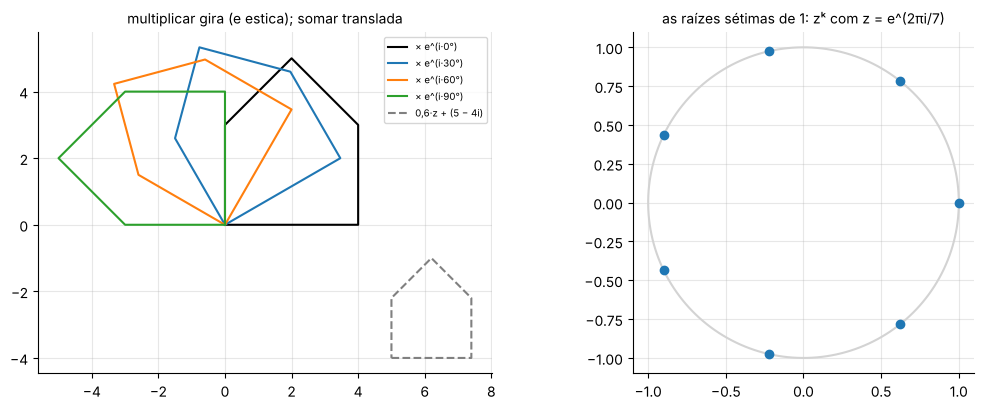

OK   z⁷ = 1 para as sete raízes:  diferença máxima = 1.34e-15


In [3]:
th, n_ = sp.symbols("theta n", real=True)
serie = sp.series(sp.exp(sp.I * th), th, 0, 10).removeO()
print("e^{iθ} até θ⁹:", sp.expand(serie))
print("   parte real:     ", sp.re(sp.expand(serie)), " (a série do cosseno)")
print("   parte imaginária:", sp.im(sp.expand(serie)), " (a série do seno)")
print("e^{iθ} − (cos θ + i sen θ) =", sp.simplify(sp.exp(sp.I * th).rewrite(sp.cos) - (sp.cos(th) + sp.I * sp.sin(th))))
t1, t2 = sp.symbols("theta1 theta2", real=True)
prod = sp.expand((sp.cos(t1) + sp.I * sp.sin(t1)) * (sp.cos(t2) + sp.I * sp.sin(t2)))
print("(cos θ1 + i sen θ1)(cos θ2 + i sen θ2) − (cos(θ1+θ2) + i sen(θ1+θ2)) =",
      sp.simplify(prod - (sp.cos(t1 + t2) + sp.I * sp.sin(t1 + t2))), "  ← as fórmulas de soma de arcos, de graça")

z1, z2 = 2 * cmath.exp(1j * 0.5), 1.5 * cmath.exp(1j * 1.2)
confere("|z1 z2| = |z1||z2|", abs(z1 * z2), 3.0, tol=1e-15)
confere("arg(z1 z2) = arg z1 + arg z2", cmath.phase(z1 * z2), 1.7, tol=1e-15)

# girar uma figura multiplicando por e^{iθ}; as raízes da unidade
casa = np.array([0, 4, 4 + 3j, 2 + 5j, 3j, 0])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for k, cor in zip(range(4), ["k", "tab:blue", "tab:orange", "tab:green"]):
    w = cmath.exp(1j * k * np.pi / 6)
    ax[0].plot((w * casa).real, (w * casa).imag, color=cor, label=f"× e^(i·{30 * k}°)")
ax[0].plot((0.6 * casa + (5 - 4j)).real, (0.6 * casa + (5 - 4j)).imag, "--", color="gray", label="0,6·z + (5 − 4i)")
ax[0].set_aspect("equal"); ax[0].legend(fontsize=7); ax[0].set_title("multiplicar gira (e estica); somar translada", fontsize=10)
raizes = np.exp(2j * np.pi * np.arange(7) / 7)
ax[1].plot(np.cos(np.linspace(0, 2 * np.pi, 200)), np.sin(np.linspace(0, 2 * np.pi, 200)), color="lightgray")
ax[1].plot(raizes.real, raizes.imag, "o"); ax[1].set_aspect("equal"); ax[1].set_title("as raízes sétimas de 1: zᵏ com z = e^(2πi/7)", fontsize=10)
plt.tight_layout(); plt.show()
confere("z⁷ = 1 para as sete raízes", raizes**7, np.ones(7), tol=1e-14)

---

## 3. O grupo das rotações $U(1)$

Os complexos de módulo 1 formam um **grupo** com a multiplicação: o produto de dois deles tem módulo 1, e o inverso de $e^{i\theta}$ é o conjugado, $e^{-i\theta}$. É o grupo $U(1)$, o círculo unitário. Ele **é** o grupo das rotações do plano, $SO(2)$, escrito de outra forma: a rotação de $\theta$ é a multiplicação por $e^{i\theta}$.

**O enrolamento sai da composição.** No domínio III, o ângulo era guardado como um número, e cada composição precisava de $\mathrm{wrap}(\theta_1+\theta_2)$. Guardando a rotação como o complexo $q=e^{i\theta}$, a composição é $q_1q_2$, e não há nada a enrolar: $e^{i(\theta+2\pi)}$ e $e^{i\theta}$ **são o mesmo número**. Duas representações da mesma rotação deixam de existir.

**E volta no $\mathrm{Log}$.** Para ter o ângulo de volta, $\theta=\arg q$, é preciso escolher um representante: o **ramo principal**, em $(-\pi,\pi]$. O $\mathrm{Log}$ complexo tem uma **descontinuidade** sobre o semieixo real negativo: dois complexos vizinhos, um logo acima e outro logo abaixo de $-1$, têm argumentos $\approx+\pi$ e $\approx-\pi$. É o mesmo salto do `wrap`, agora num lugar fixo do plano (o "corte" do logaritmo).

compor 3,0 rad e 0,4 rad: q1·q2 = -0.966798-0.255541j;  arg = -2.883185  (= 3,4 − 2π = -2.883185)
OK   e^{i(θ+2π)} = e^{iθ}: a mesma rotação, o mesmo número:  diferença máxima = 0.00e+00
OK   o inverso de uma rotação é o conjugado:  diferença máxima = 1.11e-16
OK   compor rotações comuta:  diferença máxima = 0.00e+00
arg((-1+1e-12j)) = +3.141592653589
arg((-1-1e-12j)) = -3.141592653589
arg((-1+0j)) = +3.141592653590
arg((-1+0j)) = +3.141592653590
dois vizinhos de −1, um acima e outro abaixo do eixo real: argumentos ≈ +π e ≈ −π (o corte do logaritmo)


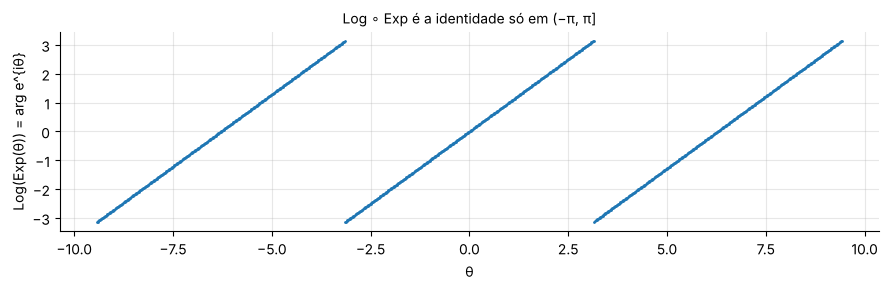

In [4]:
q1, q2 = cmath.exp(1j * 3.0), cmath.exp(1j * 0.4)
print(f"compor 3,0 rad e 0,4 rad: q1·q2 = {q1 * q2:.6f};  arg = {cmath.phase(q1 * q2):.6f}  (= 3,4 − 2π = {3.4 - 2 * math.pi:.6f})")
confere("e^{i(θ+2π)} = e^{iθ}: a mesma rotação, o mesmo número", cmath.exp(1j * (0.7 + 2 * math.pi)), cmath.exp(1j * 0.7), tol=1e-15)
confere("o inverso de uma rotação é o conjugado", q1 * q1.conjugate(), 1.0, tol=1e-15)
confere("compor rotações comuta", q1 * q2, q2 * q1, tol=0)

for z_ in [-1 + 1e-12j, -1 - 1e-12j, -1 + 0j, -1 - 0j]:
    print(f"arg({z_}) = {cmath.phase(z_):+.12f}")
print("dois vizinhos de −1, um acima e outro abaixo do eixo real: argumentos ≈ +π e ≈ −π (o corte do logaritmo)")

thetas = np.linspace(-3 * np.pi, 3 * np.pi, 1000)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(thetas, np.angle(np.exp(1j * thetas)), ".", ms=2)
ax.set_xlabel("θ"); ax.set_ylabel("Log(Exp(θ)) = arg e^{iθ}"); ax.set_title("Log ∘ Exp é a identidade só em (−π, π]", fontsize=10)
plt.tight_layout(); plt.show()

---

## 4. Complexos em `float`

**O módulo que escorrega.** Em aritmética exata, multiplicar números de módulo 1 dá módulo 1. Em `float`, nem o primeiro fator tem módulo exatamente 1: `cmath.exp(0.1j)` é o complexo de `float` mais próximo de $e^{0{,}1i}$, e o módulo dele difere de 1 por algo da ordem de $10^{-17}$. Compondo esta rotação um milhão de vezes, os erros se acumulam. A célula compara três maneiras de girar $10^6$ vezes de 0,1 rad:
- **multiplicando complexos:** $q\leftarrow q\,w$;
- **somando ângulos:** $\theta\leftarrow\theta+0{,}1$, e calculando $e^{i\theta}$ só no fim;
- **multiplicando e renormalizando** a cada passo: $q\leftarrow q\,w/\lvert q\,w\rvert$.

A referência é calculada com 40 dígitos pelo `mpmath`.

In [5]:
import mpmath as mp
mp.mp.dps = 40
N, passo = 10**6, 0.1
w = cmath.exp(1j * passo)
from fractions import Fraction
desvio = float((Fraction(w.real)**2 + Fraction(w.imag)**2 - 1) / 2)       # |w| − 1, calculado exatamente
print(f"abs(w) − 1 = {abs(w) - 1:.3e}  (o arredondamento do próprio abs esconde a diferença)")
print(f"|w| − 1 exato (com Fraction) = {desvio:.3e}")
q, qn, theta = 1 + 0j, 1 + 0j, 0.0
modulos = {}
for k in range(1, N + 1):
    q *= w
    qn *= w; qn /= abs(qn)
    theta += passo
    if k in (10**3, 10**4, 10**5, 10**6):
        modulos[k] = abs(q) - 1
exato = complex(mp.expj(mp.mpf(N) * mp.mpf(passo)))       # e^{i·N·0,1} com o 0,1 do float, em 40 dígitos
print("\n   passos    |q| − 1 (multiplicando)")
for k, m_ in modulos.items():
    print(f"{k:9d}    {m_:+.3e}")
print(f"\nerro final contra a referência:")
print(f"   multiplicando complexos:      {abs(q - exato):.2e}")
print(f"   multiplicando e renormalizando: {abs(qn - exato):.2e}")
print(f"   somando ângulos:              {abs(cmath.exp(1j * theta) - exato):.2e}   (θ acumulado = {theta:.10f}, devia ser {N * passo:.1f} com o 0,1 do float)")
confere("|q| − 1 cresce linearmente com o número de passos", modulos[10**6] / modulos[10**3], 1000, tol=0.02, relativo=True)
confere("e é o que |w|^N prevê: |q| − 1 ≈ N(|w| − 1)", modulos[10**6], N * desvio, tol=0.01, relativo=True)

abs(w) − 1 = 0.000e+00  (o arredondamento do próprio abs esconde a diferença)
|w| − 1 exato (com Fraction) = 5.444e-17



   passos    |q| − 1 (multiplicando)
     1000    +5.507e-14
    10000    +5.480e-13
   100000    +5.438e-12
  1000000    +5.456e-11

erro final contra a referência:
   multiplicando complexos:      5.52e-11
   multiplicando e renormalizando: 8.64e-12
   somando ângulos:              1.33e-06   (θ acumulado = 100000.0000013329, devia ser 100000.0 com o 0,1 do float)
OK   |q| − 1 cresce linearmente com o número de passos:  diferença relativa máxima = 9.23e-03
OK   e é o que |w|^N prevê: |q| − 1 ≈ N(|w| − 1):  diferença relativa máxima = 2.21e-03


**Leitura.**
- O módulo cresce **linearmente**: depois de $10^3$ passos, $\lvert q\rvert-1\approx5\times10^{-14}$; depois de $10^6$, mil vezes mais. É sistemático: o `float` mais próximo de $e^{0{,}1i}$ tem módulo $1+5{,}4\times10^{-17}$ (o `abs` arredonda isso para 1, e só a conta exata com `Fraction` mostra), e $\lvert q\rvert=\lvert w\rvert^k\approx1+k\cdot5{,}4\times10^{-17}$, como a segunda conferência confirma. Com um milhão de passos, o erro ainda é pequeno ($10^{-10}$), mas um integrador que roda por horas a 1 kHz faz bilhões de passos.
- **Somar ângulos é muito pior** aqui: o erro final é de $10^{-6}$, porque o ângulo acumulado chega a $10^5$ e cada soma perde os dígitos finais do 0,1 (é a soma ingênua do notebook I(a); a soma de Kahan resolveria). O complexo nunca cresce, e não sofre disso.
- **Renormalizar** corrige o módulo e reduz o erro final umas seis vezes; o que sobra é erro no **ângulo**, que a renormalização não toca.

Esta escolha (guardar a rotação como ângulo, ou como um objeto de módulo 1 e renormalizar de tempos em tempos) volta em todos os domínios seguintes. Nos quaternions, renormalizar é parte de todo integrador de atitude.

**A divisão que transborda.** A fórmula de escola, $\dfrac{a+ib}{c+id}=\dfrac{(ac+bd)+i(bc-ad)}{c^2+d^2}$, eleva $c$ e $d$ ao quadrado, e transborda com números da ordem de $10^{200}$, como a norma ingênua do notebook II(a). O Python divide complexos com um algoritmo que reescala antes (o de Smith, ou uma variante), e acerta.

In [6]:
num, den = 1e200 + 1e200j, 1e200 + 1e200j
a_, b_, c2, d2 = num.real, num.imag, den.real, den.imag
ingenua = complex(a_ * c2 + b_ * d2, b_ * c2 - a_ * d2) / (c2 * c2 + d2 * d2)
print(f"(1e200 + 1e200i)/(1e200 + 1e200i):  fórmula de escola = {ingenua};  Python = {num / den}")
confere("a divisão do Python acerta onde a fórmula de escola transborda", num / den, 1.0, tol=0)

(1e200 + 1e200i)/(1e200 + 1e200i):  fórmula de escola = (nan+nanj);  Python = (1+0j)
OK   a divisão do Python acerta onde a fórmula de escola transborda:  diferença máxima = 0.00e+00


---

## 5. O passo complexo: derivadas quase exatas sem números duais

O notebook III(a) derivou com números duais, $f(x+\varepsilon)=f(x)+\varepsilon f'(x)$. Com $i$ no lugar de $\varepsilon$ e um passo $h$ real pequeno, a série de Taylor dá

$$f(x+ih)=f(x)+ih\,f'(x)-\frac{h^2}{2}f''(x)-i\frac{h^3}{6}f'''(x)+\dots\quad\Longrightarrow\quad f'(x)=\frac{\operatorname{Im}f(x+ih)}{h}+O(h^2).$$

Duas diferenças em relação às diferenças finitas do notebook I(a):
- **não há subtração**: a derivada sai da parte imaginária, sem subtrair dois números quase iguais. Então não há cancelamento, e o passo pode ser tão pequeno quanto se queira, $h=10^{-200}$, por exemplo;
- o erro de truncamento é $O(h^2)$, que com $h=10^{-200}$ é zero em `float`.

E uma diferença em relação aos números duais: **não é preciso escrever uma classe**. O NumPy já sabe calcular `sin`, `exp`, `sqrt` de complexos. O preço: a função tem de ser **analítica** (feita de operações que fazem sentido com complexos). `abs(x)`, `max`, comparações e a parte real de um complexo, que o código "real" às vezes usa, quebram o método, porque destroem a parte imaginária. Os notebooks 3 e 5 da série Kalman usam o passo complexo para conferir jacobianos.

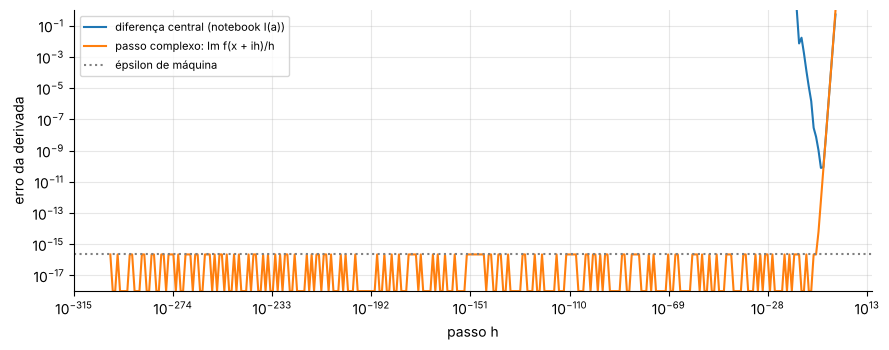

passo complexo com h = 1e-200: erro 0.0e+00
OK   passo complexo com h = 1e-200 = derivada exata:  diferença relativa máxima = 0.00e+00

f(x) = |x|·x em x = 2: derivada certa = 4;  passo complexo dá 2.0000  ← errado


In [7]:
f = lambda x: np.exp(np.sin(x))
x0 = 1.0
exata = np.cos(x0) * np.exp(np.sin(x0))
hs = np.logspace(-300, 0, 300)
e_complexo = np.abs(np.imag(f(x0 + 1j * hs)) / hs - exata)
e_central = np.abs((f(x0 + hs) - f(x0 - hs)) / (2 * hs) - exata)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.loglog(hs, e_central + 1e-18, label="diferença central (notebook I(a))")
ax.loglog(hs, e_complexo + 1e-18, label="passo complexo: Im f(x + ih)/h")
ax.axhline(np.finfo(float).eps, ls=":", color="gray", label="épsilon de máquina")
ax.set_xlabel("passo h"); ax.set_ylabel("erro da derivada"); ax.set_ylim(1e-18, 1); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"passo complexo com h = 1e-200: erro {abs(np.imag(f(x0 + 1e-200j)) / 1e-200 - exata):.1e}")
confere("passo complexo com h = 1e-200 = derivada exata", np.imag(f(x0 + 1e-200j)) / 1e-200, exata, tol=4e-16, relativo=True)

g_abs = lambda x: np.abs(x) * x            # não analítica: abs destrói a parte imaginária
print(f"\nf(x) = |x|·x em x = 2: derivada certa = 4;  passo complexo dá {np.imag(g_abs(2 + 1e-20j)) / 1e-20:.4f}  ← errado")

**Leitura.** A diferença central só aparece na ponta direita do eixo (para $h$ menor que uns $10^{-16}$, ela dá zero ou lixo), com o "V" do dilema do passo (notebook I(a)) e o melhor erro em torno de $10^{-11}$. O passo complexo cai como $h^2$ até a precisão da máquina, por volta de $h=10^{-8}$, e **fica lá** para todo passo menor, até $10^{-300}$. Na prática, é tão bom quanto um número dual, sem precisar de classe nenhuma. O último exemplo mostra o limite: com `abs`, o método dá uma resposta errada **sem avisar**. (O valor sai como se $\lvert x\rvert$ fosse $\lvert x+ih\rvert$, um número real, e a parte imaginária só "vê" o fator $x$.)

---

## 6. A interface de domínio para as rotações do plano

O domínio IV guarda a **rotação** como um complexo unitário $q=e^{i\theta}$. As translações continuam sendo somas (é o domínio II, escrito com $z=x+iy$); juntar as duas é o assunto do domínio V.

| operação | domínio III (ângulo) | domínio IV (complexo unitário) |
|---|---|---|
| `compoe(g, h)` | $\mathrm{wrap}(\theta_g+\theta_h)$ | $q_gq_h$ |
| `inverso(g)` | $\mathrm{wrap}(-\theta_g)$ | $\bar q_g$ |
| `identidade` | $0$ | $1$ |
| `Exp(ξ)` | $\mathrm{wrap}(\xi)$ | $e^{i\xi}$ |
| `Log(g)` | $\theta_g$ | $\arg q_g\in(-\pi,\pi]$ |
| $x\boxplus\delta$ | $\mathrm{wrap}(\theta+\delta)$ | $q\,e^{i\delta}$ |

Os dois domínios descrevem o **mesmo grupo**. A conferência final mostra que, partindo dos mesmos ângulos, as duas representações dão as mesmas respostas.

In [8]:
class DominioU1:
    """Domínio IV: as rotações do plano como complexos de módulo 1."""
    nome = "U(1) (complexos unitários)"
    dim = 1
    identidade = 1 + 0j
    def compoe(self, g, h): return g * h
    def inverso(self, g):   return np.conj(g)
    def Exp(self, xi):      return np.exp(1j * xi)
    def Log(self, g):       return np.angle(g)
    def mais(self, x, d):   return self.compoe(x, self.Exp(d))
    def menos(self, y, x):  return self.Log(self.compoe(self.inverso(x), y))

def testa_dominio(D, amostra, tol=1e-12):
    """Os mesmos testes dos domínios anteriores."""
    g, h, k = amostra(), amostra(), amostra()
    print(f"domínio {D.nome}")
    confere("  associatividade da composição", D.menos(D.compoe(D.compoe(g, h), k), D.compoe(g, D.compoe(h, k))), 0, tol)
    confere("  identidade", D.menos(D.compoe(g, D.identidade), g), 0, tol)
    confere("  inverso", D.menos(D.compoe(g, D.inverso(g)), D.identidade), 0, tol)
    d = D.Log(amostra()) * 0.3
    confere("  Log(Exp(δ)) = δ", D.Log(D.Exp(d)), d, tol)
    confere("  (x ⊞ δ) ⊟ x = δ", D.menos(D.mais(g, d), g), d, tol)
    confere("  x ⊞ (y ⊟ x) = y", D.menos(D.mais(g, D.menos(h, g)), h), 0, tol)

U = DominioU1()
testa_dominio(U, lambda: np.exp(1j * rng.uniform(-np.pi, np.pi)))

def wrap(a): return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)
angulos = rng.uniform(-np.pi, np.pi, (1000, 2))
comp_angulo = wrap(angulos[:, 0] + angulos[:, 1])
comp_complexo = U.Log(U.compoe(U.Exp(angulos[:, 0]), U.Exp(angulos[:, 1])))
confere("compor no domínio IV = compor no domínio III (1000 pares; a diferença é só ±π ≡ ∓π)",
        np.abs(np.exp(1j * comp_angulo) - np.exp(1j * comp_complexo)), np.zeros(1000), tol=1e-14)

domínio U(1) (complexos unitários)
OK     associatividade da composição:  diferença máxima = 0.00e+00
OK     identidade:  diferença máxima = 0.00e+00
OK     inverso:  diferença máxima = 0.00e+00
OK     Log(Exp(δ)) = δ:  diferença máxima = 1.11e-16
OK     (x ⊞ δ) ⊟ x = δ:  diferença máxima = 1.11e-16
OK     x ⊞ (y ⊟ x) = y:  diferença máxima = 1.39e-17
OK   compor no domínio IV = compor no domínio III (1000 pares; a diferença é só ±π ≡ ∓π):  diferença máxima = 9.55e-16


**Para pensar.** Se as duas representações descrevem o mesmo grupo, por que mudar? Três razões, que crescem nos domínios seguintes:
1. **A composição não precisa de exceções.** Nenhum `wrap`, nenhuma comparação com $\pi$. Nos quaternions (domínio VI), uma representação por ângulos (os ângulos de Euler) tem singularidades de verdade (o *gimbal lock*), e a representação por números de módulo 1 não tem.
2. **Girar um vetor é uma multiplicação.** Para girar o ponto $z$, basta $qz$, sem senos nem cossenos.
3. **O preço é conhecido e barato:** renormalizar $q$ de vez em quando.

---

## 7. Exercícios

1. **Kahan no ângulo.** Refaça a seção 4 somando os ângulos com a soma compensada de Kahan (notebook I(a)). O erro final fica parecido com o do complexo?
2. **Renormalizar de vez em quando.** Na seção 4, renormalize só a cada 1000 passos. O módulo fica bom? Qual é o custo, em tempo, de renormalizar a cada passo?
3. **Raízes da unidade e o FFT.** As raízes $n$-ésimas de 1 são a base da transformada de Fourier discreta. Mostre que $\sum_{k=0}^{n-1}e^{2\pi ijk/n}=0$ para $j=1,\dots,n-1$, com o `sympy` para $n=7$ e numericamente para $n=1000$.
4. **Passo complexo em código "real".** Escreva uma função com um `if x > 0` e veja o que o passo complexo faz quando `x` é complexo (o Python compara complexos?). Como reescrever a função para o passo complexo funcionar?
5. **Semelhanças.** Mostre que a composição de $z\mapsto a_1z+b_1$ com $z\mapsto a_2z+b_2$ é outra transformação do mesmo tipo, e escreva o par $(a,b)$ resultante. A composição comuta? Este é o grupo do domínio V (com $\lvert a\rvert=1$).